In [1]:
from datasets import load_dataset
import numpy 
from transformers import (
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    AutoModel,
    AutoTokenizer
)
import torch
from torch.utils.data import DataLoader


In [2]:
MODEL_NAME = "dumitrescustefan/bert-base-romanian-cased-v1"

In [3]:
dataset = load_dataset("community-datasets/ronec")

label_list = dataset["train"].features["ner_tags"].feature.names



README.md:   0%|          | 0.00/10.2k [00:00<?, ?B/s]

ronec/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.14MB            

ronec/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ronec/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  323kB            

ronec/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ronec/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  473kB            

ronec/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1330 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [4]:
id2label = {i: l for i, l in enumerate(label_list)}
num_labels = len(label_list)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/29.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/397k [00:00<?, ?B/s]

In [7]:
def tokenize_and_align_labels(examples):
    tokenized = tokenizer(
        examples["tokens"],
        truncation = True,
        max_length = 128,
        is_split_into_words = True
    )


    aligned_labels = []
    for i, word_labels in enumerate(examples["ner_tags"]):
        word_ids = tokenized.word_ids(batch_index = i)

        prev_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            if word_idx is None or word_idx == prev_word_idx:
                label_ids.append(-100)
            else:
                label_ids.append(word_labels[word_idx])
            prev_word_idx = word_idx

        aligned_labels.append(label_ids)
    tokenized["labels"] = aligned_labels
    return tokenized

In [8]:
tokenized_dataset = dataset.map(
    tokenize_and_align_labels,
    batched = True,
    remove_columns = dataset["train"].column_names
)

collator = DataCollatorForTokenClassification(tokenizer = tokenizer)

# load train / valid / test ds using 
train_loader = DataLoader(tokenized_dataset["train"],
                        batch_size = 16,
                        shuffle = True,
                        collate_fn = collator)
val_loader = DataLoader(tokenized_dataset["validation"],
                        batch_size = 32,
                        shuffle = False,
                        collate_fn = collator)
test_loader = DataLoader(tokenized_dataset["test"],
                        batch_size = 32,
                        shuffle = False,
                        collate_fn = collator)

Map:   0%|          | 0/9000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1330 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [9]:
!pip install -q pytorch-crf seqeval evaluate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


this is some reference on how our model sturcture works
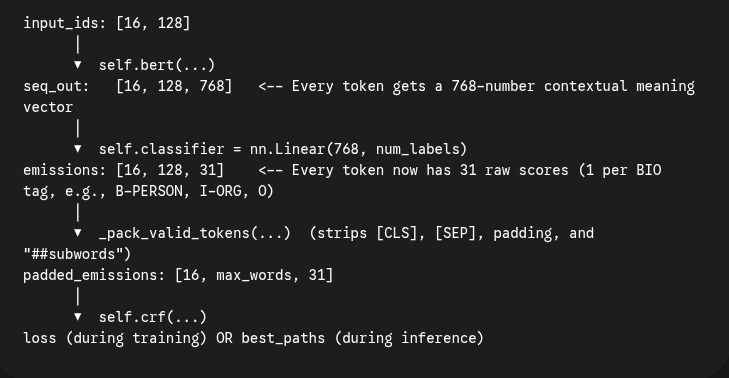

In [11]:
# custom model - robert + crf layer
from torchcrf import CRF
import torch.nn as nn

class RoBERT_CRF(nn.Module):
    def __init__(self, model_name, num_labels):
        super().__init__()
        self.bert = AutoModel.from_pretrained(MODEL_NAME)
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)
        self.crf = CRF(num_labels, batch_first = True)

    # we get only the tokens that matter, removing the subword ones and models [SEP], [PAD]...
    def _pack_valid_tokens(self, emissions, labels):
        """
        Extracts only real word-start tokens (labels != -100) per sentence and pads them,
        satisfying pytorch-crf's requirement that mask[:, 0] is always True and labels >= 0.
        """
        batch_size, _, num_tags = emissions.shape
        valid_emissions, valid_labels, lengths = [], [], []

        for b in range(batch_size):
            keep = labels[b] != -100
            valid_emissions.append(emissions[b][keep])
            valid_labels.append(labels[b][keep])
            lengths.append(keep.sum().item())

        max_len = max(max(lengths), 1)
        padded_emissions = torch.zeros(batch_size, max_len, num_tags, device=emissions.device)
        padded_labels = torch.zeros(batch_size, max_len, dtype=torch.long, device=emissions.device)
        mask = torch.zeros(batch_size, max_len, dtype=torch.bool, device=emissions.device)

        for b, length in enumerate(lengths):
            if length > 0:
                padded_emissions[b, :length] = valid_emissions[b]
                padded_labels[b, :length] = valid_labels[b]
                mask[b, :length] = True
            else:
                mask[b, 0] = True  # safety fallback for empty sequences

        return padded_emissions, padded_labels, mask

    def forward(self, input_ids, attention_mask, labels):
        seq_out = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        emissions = self.classifier(self.dropout(seq_out))

        padded_emissions, padded_labels, mask = self._pack_valid_tokens(emissions, labels)
        # CRF returns log-likelihood -> negate for minimization loss
        loss = -self.crf(padded_emissions, padded_labels, mask=mask, reduction="mean")
        return loss

    @torch.no_grad()
    def decode(self, input_ids, attention_mask, labels):
        seq_out = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        emissions = self.classifier(seq_out)
        padded_emissions, padded_labels, mask = self._pack_valid_tokens(emissions, labels)

        # Viterbi decoding returns a list of valid tag ID lists (one per sentence)
        best_paths = self.crf.decode(padded_emissions, mask=mask)
        gold_paths = [
            padded_labels[b][mask[b]].cpu().tolist()
            for b in range(len(best_paths))
        ]
        # gold means true labels from the dataset
        return best_paths, gold_paths


In [12]:
import torch



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RoBERT_CRF(MODEL_NAME, num_labels).to(device)

print(device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  500MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


cuda


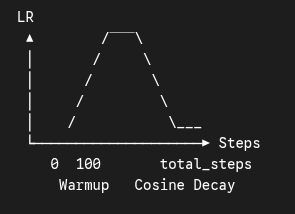

In [14]:
# using custom lr-s for each part of the custom model we created

optimizer = torch.optim.AdamW([
    {"params": model.bert.parameters(), "lr": 3e-5},
    {"params": model.classifier.parameters(), "lr": 1e-3},
    {"params": model.crf.parameters(), "lr": 1e-3}
], weight_decay = 0.01)

In [15]:
import evaluate
from transformers import get_cosine_schedule_with_warmup

# we use this in order to start the training steps small -> get bigger -> to the final steps we get gradually thiner for more fine detail
# use it because classifier and crf layer start random => smaller impact at first with gradual effect on the bert model further
epochs = 3
scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps = 100,
    num_training_steps = len(train_loader) * epochs
)

seqeval = evaluate.load("seqeval")



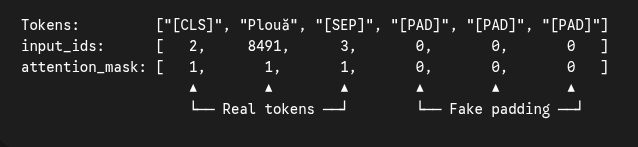
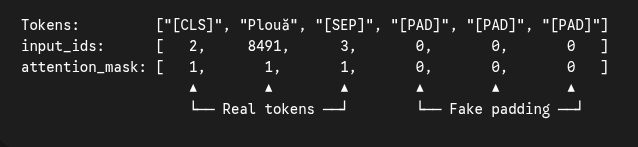
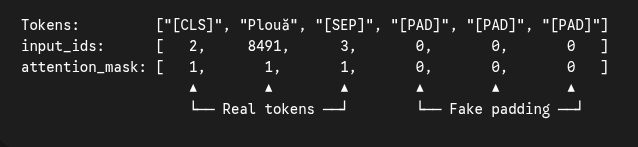

In [21]:
def evaluate_metric(loader):
    model.eval()
    all_preds, all_golds = [], []

    for batch in loader:
        preds_ids, gold_ids = model.decode(
            batch["input_ids"].to(device),
            batch["attention_mask"].to(device),
            batch["labels"].to(device)
        )
        all_preds.extend([[id2label[i] for i in seq] for seq in preds_ids])
        all_golds.extend([[id2label[i] for i in seq] for seq in gold_ids])

    return seqeval.compute(predictions = all_preds, references = all_golds)



In [22]:
from tqdm.auto import tqdm

best_f1 = 0.0
log_every = 50  # prints an extra status update every 50 batches

for epoch in range(1, epochs + 1):
    model.train()
    total_loss = 0.0

    # tqdm creates a live progress bar with ETA, speed (it/s), and live loss
    progress_bar = tqdm(enumerate(train_loader, start=1), total=len(train_loader), desc=f"Epoch {epoch}/{epochs}")

    for step, batch in progress_bar:
        optimizer.zero_grad()
        loss = model(
            batch["input_ids"].to(device),
            batch["attention_mask"].to(device),
            batch["labels"].to(device),
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

        # Live update on the progress bar every batch
        current_lr = scheduler.get_last_lr()[0]
        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            avg_loss=f"{total_loss / step:.4f}",
            lr=f"{current_lr:.2e}"
        )

    # Validation check at the end of the epoch
    val_res = evaluate_metric(val_loader)
    val_f1 = val_res["overall_f1"]
    print(
        f"\nEpoch {epoch} Summary | Avg Train Loss: {total_loss/len(train_loader):.4f} "
        f"| Val Precision: {val_res['overall_precision']:.4f} "
        f"| Val Recall: {val_res['overall_recall']:.4f} "
        f"| Val F1: {val_f1:.4f}\n"
    )

    # Save the best model checkpoint
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), "best_robert_crf.pt")
        print(f"--> New best model saved! (Best F1: {best_f1:.4f})")

Epoch 1/3:   0%|          | 0/563 [00:00<?, ?it/s]


Epoch 1 Summary | Avg Train Loss: 3.0911 | Val Precision: 0.8844 | Val Recall: 0.9109 | Val F1: 0.8975

--> New best model saved! (Best F1: 0.8975)


Epoch 2/3:   0%|          | 0/563 [00:00<?, ?it/s]


Epoch 2 Summary | Avg Train Loss: 1.6826 | Val Precision: 0.8829 | Val Recall: 0.9131 | Val F1: 0.8977

--> New best model saved! (Best F1: 0.8977)


Epoch 3/3:   0%|          | 0/563 [00:00<?, ?it/s]


Epoch 3 Summary | Avg Train Loss: 1.4275 | Val Precision: 0.8816 | Val Recall: 0.9103 | Val F1: 0.8957



In [23]:
# load the best checkpoint
model.load_state_dict(torch.load("best_robert_crf.pt"))
test_res = evaluate_metric(test_loader)

print(f"\nOfficial RoNEC Test F1 (RoBERT + CRF): {test_res['overall_f1']:.4f}")


Official RoNEC Test F1 (RoBERT + CRF): 0.8949


In [25]:
from datasets import load_dataset

# Rebuild label_list and label2id if the runtime restarted or skipped that cell
if "label_list" not in globals():
    dataset = load_dataset("ronec")
    label_list = dataset["train"].features["ner_tags"].feature.names

label2id = {label: i for i, label in enumerate(label_list)}

# Now inspect the learned CRF transition scores
o_id = label2id["O"]
i_per_id = label2id["I-PERSON"]
b_per_id = label2id["B-PERSON"]

print("O -> I-PERSON:", model.crf.transitions[o_id, i_per_id].item())
print("B-PERSON -> I-PERSON:", model.crf.transitions[b_per_id, i_per_id].item())

O -> I-PERSON: -0.37873414158821106
B-PERSON -> I-PERSON: 0.2761389911174774


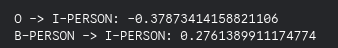

In [26]:
import torch

def predict_ner_ro(sentence_words, model, tokenizer, id2label, device):
    model.eval()
    enc = tokenizer(
        sentence_words,
        is_split_into_words=True,
        return_tensors="pt",
        truncation=True,
        max_length=128,
    )
    word_ids = enc.word_ids(batch_index=0)

    # Mark only first subword of each word with 0, everything else with -100
    dummy_labels = []
    prev_w = None
    for w_id in word_ids:
        if w_id is None or w_id == prev_w:
            dummy_labels.append(-100)
        else:
            dummy_labels.append(0)
        prev_w = w_id

    labels_tensor = torch.tensor([dummy_labels], dtype=torch.long, device=device)
    pred_ids, _ = model.decode(
        enc["input_ids"].to(device),
        enc["attention_mask"].to(device),
        labels_tensor,
    )

    for word, tag_id in zip(sentence_words, pred_ids[0]):
        print(f"{word:18s} -> {id2label[tag_id]}")

# Test on your own Romanian sentence!
sample = ["Andrei", "Ionescu", "a", "semnat", "un", "contract", "de", "5000", "de", "lei", "la", "Banca", "Transilvania", "în", "Brașov", "."]
predict_ner_ro(sample, model, tokenizer, id2label, device)

Andrei             -> B-PERSON
Ionescu            -> I-PERSON
a                  -> O
semnat             -> O
un                 -> O
contract           -> O
de                 -> O
5000               -> B-MONEY
de                 -> I-MONEY
lei                -> I-MONEY
la                 -> O
Banca              -> B-ORG
Transilvania       -> I-ORG
în                 -> O
Brașov             -> B-GPE
.                  -> O


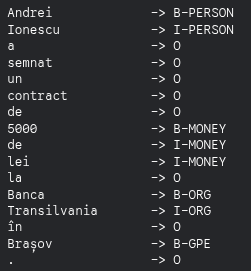